# Model comparison
The held-out test period is the final 30 days. We compare a 7-day moving-average baseline, ARIMA(2,1,2), and SARIMA(2,1,2) with weekly seasonality.

In [1]:
import sys
sys.path.insert(0, "..")  # repo root when run from nb/
import pandas as pd
from src.model import evaluate_series
df=pd.read_csv("../data/output/4 revenue_total.csv", parse_dates=["invoice_date"])
results=pd.DataFrame(evaluate_series(df.set_index("invoice_date")["revenue"],30)); results


,model,train_start,train_end,test_start,test_end,rmse,mae,mape,improvement_vs_baseline_pct
0,BASELINE,2017-11-01,2019-12-01,2019-12-02,2019-12-31,205.448352,158.503429,7.594830,0.000000
1,ARIMA,2017-11-01,2019-12-01,2019-12-02,2019-12-31,192.079532,151.108108,7.274091,6.507144
2,SARIMA,2017-11-01,2019-12-01,2019-12-02,2019-12-31,152.312627,128.597800,6.354916,25.863301


The table reports RMSE, MAE, MAPE and improvement versus baseline. The split is train = all days before the final 30 days and test = the final 30 days.

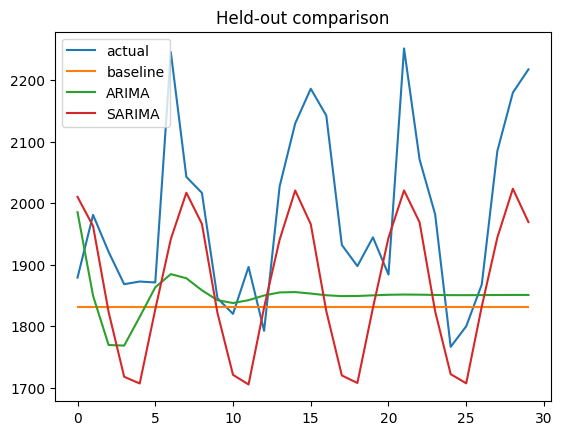

In [2]:
import matplotlib.pyplot as plt
from src.model import fit_forecaster, forecast, baseline_forecast
y=df.revenue.to_numpy(); train,test=y[:-30],y[-30:]
plt.plot(test,label="actual"); plt.plot(baseline_forecast(train,30),label="baseline"); plt.plot(forecast(fit_forecaster(train,"arima"),30),label="ARIMA"); plt.plot(forecast(fit_forecaster(train,"sarima"),30),label="SARIMA"); plt.legend(); plt.title("Held-out comparison"); plt.show()